# 04 - Model Evaluation

> Research prototype only. The dataset is simulated and labels are experimental proxies. No result here validates field deployment or early-warning lead time.

Kick recall, precision, PR-AUC and false alarms take priority over accuracy.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config
from src.predict import load_bundle
from src.evaluate import load_test_data, evaluate_all, save_results_tables, save_evaluation_plots, write_evaluation_report

config = load_config()
bundle = load_bundle(config=config)
X_test, y_test, _ = load_test_data(config, bundle['feature_columns'])
results = evaluate_all(bundle, X_test, y_test, config)

In [2]:
table = save_results_tables(results, config)
table

,model,family,decision_threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,fpr,far,tp,fp,tn,fn
0,logistic_regression,supervised,0.539932,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,175,0,300,0
1,random_forest,supervised,0.539690,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,175,0,300,0
2,xgboost,supervised,0.813345,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,175,0,300,0
3,isolation_forest,unsupervised_anomaly,0.632632,0.837895,0.694444,1.000000,0.819672,0.930581,0.878995,0.256667,0.256667,175,77,223,0
4,isolation_forest_normal_fit,unsupervised_anomaly,0.998264,0.861053,1.000000,0.622857,0.767606,1.000000,1.000000,0.000000,0.000000,109,0,300,66
5,conventional_baseline,conventional_rule,0.333617,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,175,0,300,0


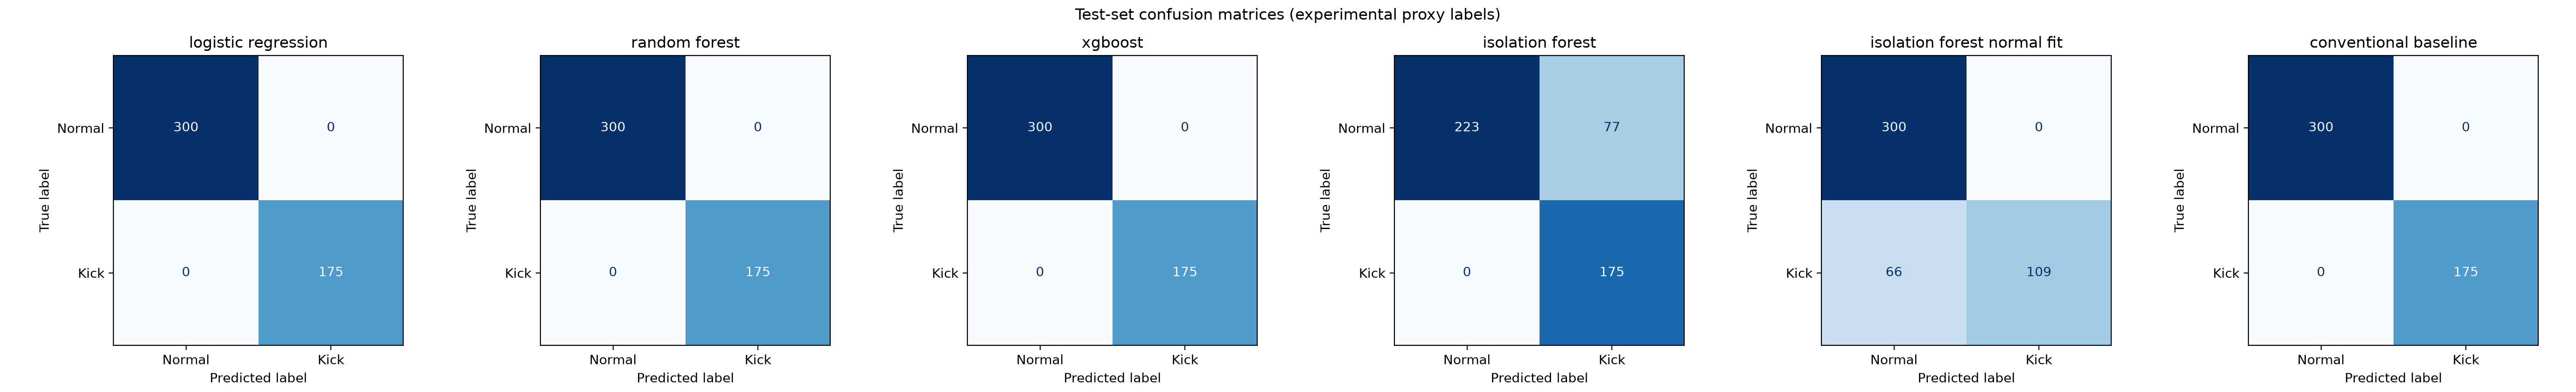

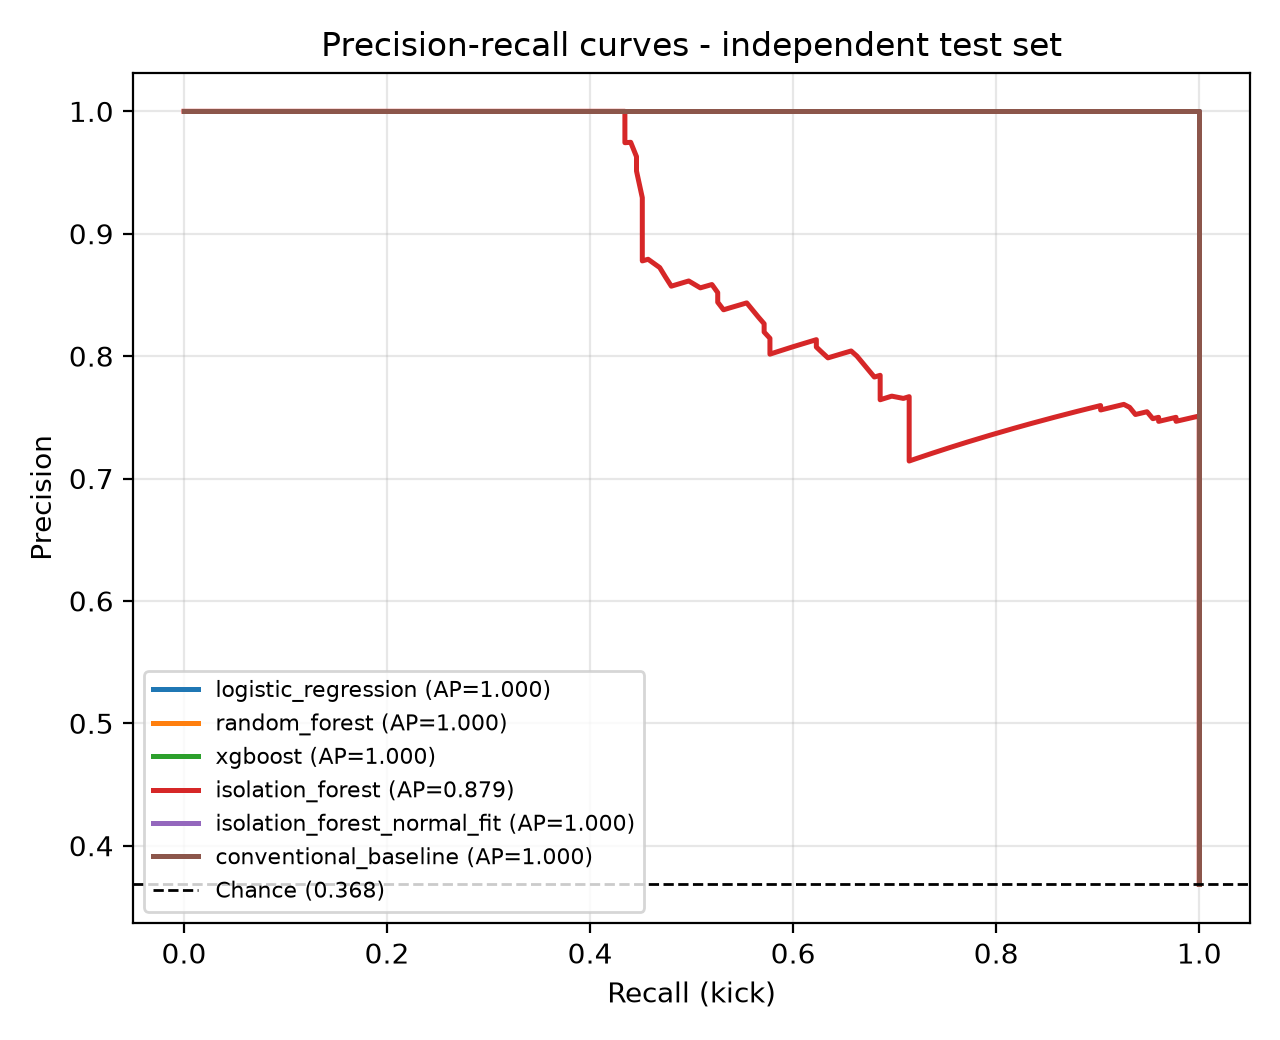

In [3]:
save_evaluation_plots(results, y_test, config)
from IPython.display import Image, display
display(Image(filename='../results/figures/confusion_matrices.png'))
display(Image(filename='../results/figures/precision_recall_curves.png'))

In [4]:
print(write_evaluation_report(results, table, config))

C:\Users\dnyak\OneDrive\Fifth_year_project\reports\model_evaluation.md
